# Practical 1 · Uber Fare Prediction

Predict the fare in USD from the pickup and drop-off coordinates. We use the straight-line distance between the points as the input to both models.

Download [Uber Fares Dataset](https://www.kaggle.com/datasets/yasserh/uber-fares-dataset), extract `uber.csv` beside this notebook, and open the notebook in VS Code. Select a Python kernel and choose **Run All**. If imports are missing, run `%pip install pandas numpy matplotlib scikit-learn` in a notebook cell.

## 1. import library and load dataset

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

df = pd.read_csv("uber.csv")

print(df.head())
print(df.shape)

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

## 2. Preprocess Dataset

In [10]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

df = df.dropna()

df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], utc=True)

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

df = df.drop("pickup_datetime", axis=1)

df = df[df["fare_amount"] > 0]
df = df[df["passenger_count"].between(1, 6)]

print(df.head())

   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  day  month  
0         40.723217                1    19    7      5  
1         40.750325                1    20   17      7  
2         40.772647                1    21   24      8  
3         40.803349                3     8   26      6  
4         40.761247                5    17   28      8  


C:\Users\Soham\AppData\Local\Temp\ipykernel_21236\2597135824.py:5: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], utc=True)
C:\Users\Soham\AppData\Local\Temp\ipykernel_21236\259713

## 2. Identify outliers

For each training column, flag values outside Q1 − 1.5 × IQR and Q3 + 1.5 × IQR, where IQR = Q3 − Q1. Keep the flagged trips because unusually long or expensive rides can be valid.

C:\Users\Soham\AppData\Roaming\Python\Python314\site-packages\seaborn\categorical.py:128: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  self.plot_data[self.orient] = ""
C:\Users\Soham\AppData\Roaming\Python\Python314\site-packages\seaborn\_b

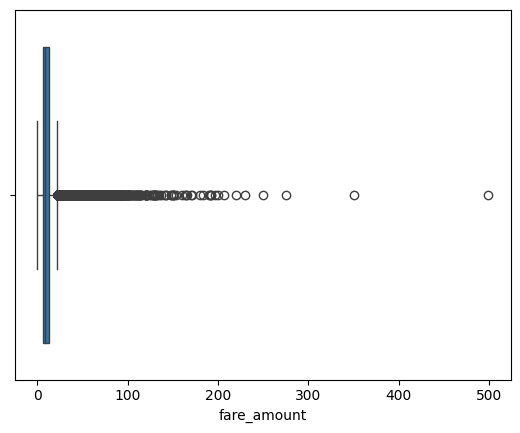

(182147, 9)


In [12]:
sns.boxplot(x=df["fare_amount"])
plt.show()

Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df["fare_amount"] >= lower) & (df["fare_amount"] <= upper)]

print(df.shape)

## 3. Check correlation

The Pearson correlation coefficient measures the linear relationship between distance and fare.

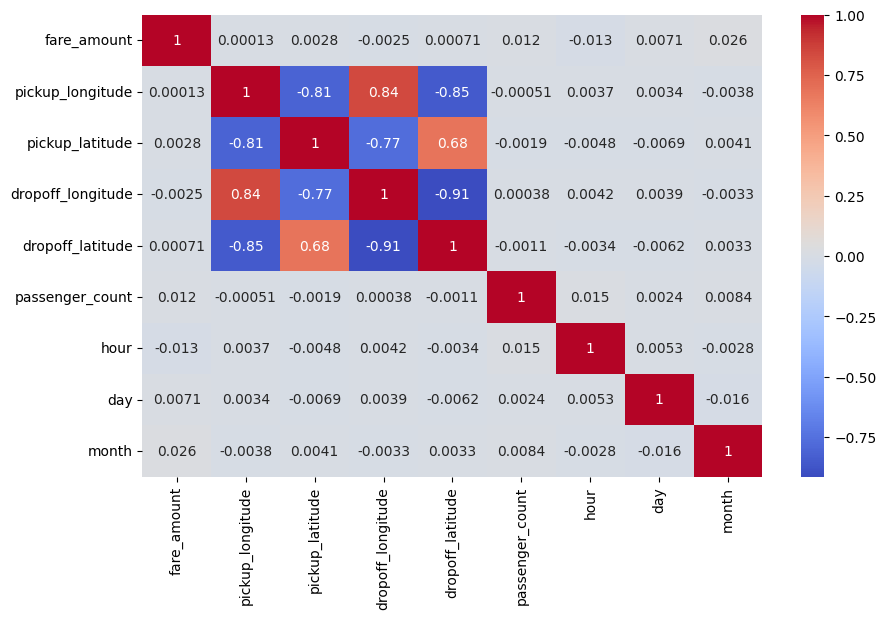

In [13]:
plt.figure(figsize=(10, 6))

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")

plt.show()

## 4.Split dataset

In [14]:
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 5. Linear regression

In [17]:
lr = LinearRegression()

lr.fit(X_train, y_train)

pred1 = lr.predict(X_test)

print("R2 Score:", r2_score(y_test, pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred1)))
print("MAE:", mean_absolute_error(y_test, pred1))

R2 Score: 0.0012124142348581834
RMSE: 4.1300971736389664
MAE: 3.284205692968938


## 5.Random Forest Regression

In [18]:
rf = RandomForestRegressor(n_estimators=50, random_state=42)

rf.fit(X_train, y_train)

pred2 = rf.predict(X_test)

print("R2 Score:", r2_score(y_test, pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))
print("MAE:", mean_absolute_error(y_test, pred2))

R2 Score: 0.717868869435033
RMSE: 2.195074207041379
MAE: 1.536231899048126


## 5. Compare both models

In [19]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2": [r2_score(y_test, pred1), r2_score(y_test, pred2)],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred1)),
        np.sqrt(mean_squared_error(y_test, pred2))
    ],
    "MAE": [
        mean_absolute_error(y_test, pred1),
        mean_absolute_error(y_test, pred2)
    ]
})

print(results)

               Model        R2      RMSE       MAE
0  Linear Regression  0.001212  4.130097  3.284206
1      Random Forest  0.717869  2.195074  1.536232
